# LeetCode #135: Candy

https://leetcode.com/problems/candy/

## Comparison of Approaches
| Approach | Time | Space |
|---|---|---|
| Brute Force | O(n²) | O(n) |
| Two-Pass Greedy ★ | O(n) | O(n) |

## Understanding the Methods
### Brute Force
Repeatedly scan the array, updating candy counts until no more updates are needed. Very slow with O(n²) worst-case.

### Optimal: Two-Pass Greedy ★
Left pass: each child with higher rating than left neighbor gets one more candy than left neighbor.
Right pass: each child with higher rating than right neighbor gets max(current, right+1) candies.
Sum all candies. Two O(n) passes, O(n) space for candy array.

## Solutions
### C#

In [ ]:
// Two-Pass Greedy O(n) time, O(n) space
public class Solution {
    public int Candy(int[] ratings) {
        int n = ratings.Length;
        int[] candies = new int[n];
        Array.Fill(candies, 1);
        for (int i = 1; i < n; i++)
            if (ratings[i] > ratings[i-1]) candies[i] = candies[i-1] + 1;
        for (int i = n-2; i >= 0; i--)
            if (ratings[i] > ratings[i+1]) candies[i] = Math.Max(candies[i], candies[i+1] + 1);
        return candies.Sum();
    }
}

### Python

In [ ]:
# Two-Pass Greedy O(n) time, O(n) space
class Solution:
    def candy(self, ratings: list[int]) -> int:
        n = len(ratings)
        candies = [1] * n
        for i in range(1, n):
            if ratings[i] > ratings[i-1]:
                candies[i] = candies[i-1] + 1
        for i in range(n-2, -1, -1):
            if ratings[i] > ratings[i+1]:
                candies[i] = max(candies[i], candies[i+1] + 1)
        return sum(candies)

### Go

In [ ]:
// Two-Pass Greedy O(n) time, O(n) space
func candy(ratings []int) int {
    n := len(ratings)
    candies := make([]int, n)
    for i := range candies { candies[i] = 1 }
    for i := 1; i < n; i++ {
        if ratings[i] > ratings[i-1] { candies[i] = candies[i-1] + 1 }
    }
    total := candies[n-1]
    for i := n-2; i >= 0; i-- {
        if ratings[i] > ratings[i+1] && candies[i] <= candies[i+1] {
            candies[i] = candies[i+1] + 1
        }
        total += candies[i]
    }
    return total
}

### Rust

In [ ]:
// Two-Pass Greedy O(n) time, O(n) space
impl Solution {
    pub fn candy(ratings: Vec<i32>) -> i32 {
        let n = ratings.len();
        let mut candies = vec![1i32; n];
        for i in 1..n {
            if ratings[i] > ratings[i-1] { candies[i] = candies[i-1] + 1; }
        }
        for i in (0..n-1).rev() {
            if ratings[i] > ratings[i+1] { candies[i] = candies[i].max(candies[i+1] + 1); }
        }
        candies.iter().sum()
    }
}

## Example Scenarios

### 1. Common Case — a valley between two peaks
**Input:** ratings = [1, 0, 2]
Left pass gives $[1,1,2]$ (only index 2 rises). Right pass bumps index 0 to 2 because $1>0$. Final candies $[2,1,2]$, total **5**.

### 2. Slightly Complex — equal neighbors break the chain
**Input:** ratings = [1, 2, 2]
Left pass: $[1,2,1]$ — index 2 is not greater than index 1, so it stays at 1. Right pass changes nothing. Equal ratings carry no constraint. Final $[1,2,1]$, total **4**.

### 3. Edge Case: Time Factor — single child
**Input:** ratings = [1]
Both passes are no-ops; the lone child gets the base 1 candy. Total **1**.

### 4. Edge Case: Space Factor — strictly ascending
**Input:** ratings = [1, 2, 3, 4, 5]
Left pass alone produces $[1,2,3,4,5]$; the right pass adds nothing. The $O(n)$ candies array dominates memory. Total $1+2+3+4+5 =$ **15**.

### 5. Almost-Impossible but Plausible — strictly descending
**Input:** ratings = [5, 4, 3, 2, 1]
Left pass stays all 1s; the right pass does all the work, yielding $[5,4,3,2,1]$. This is the case where the second pass is essential. Total **15**.


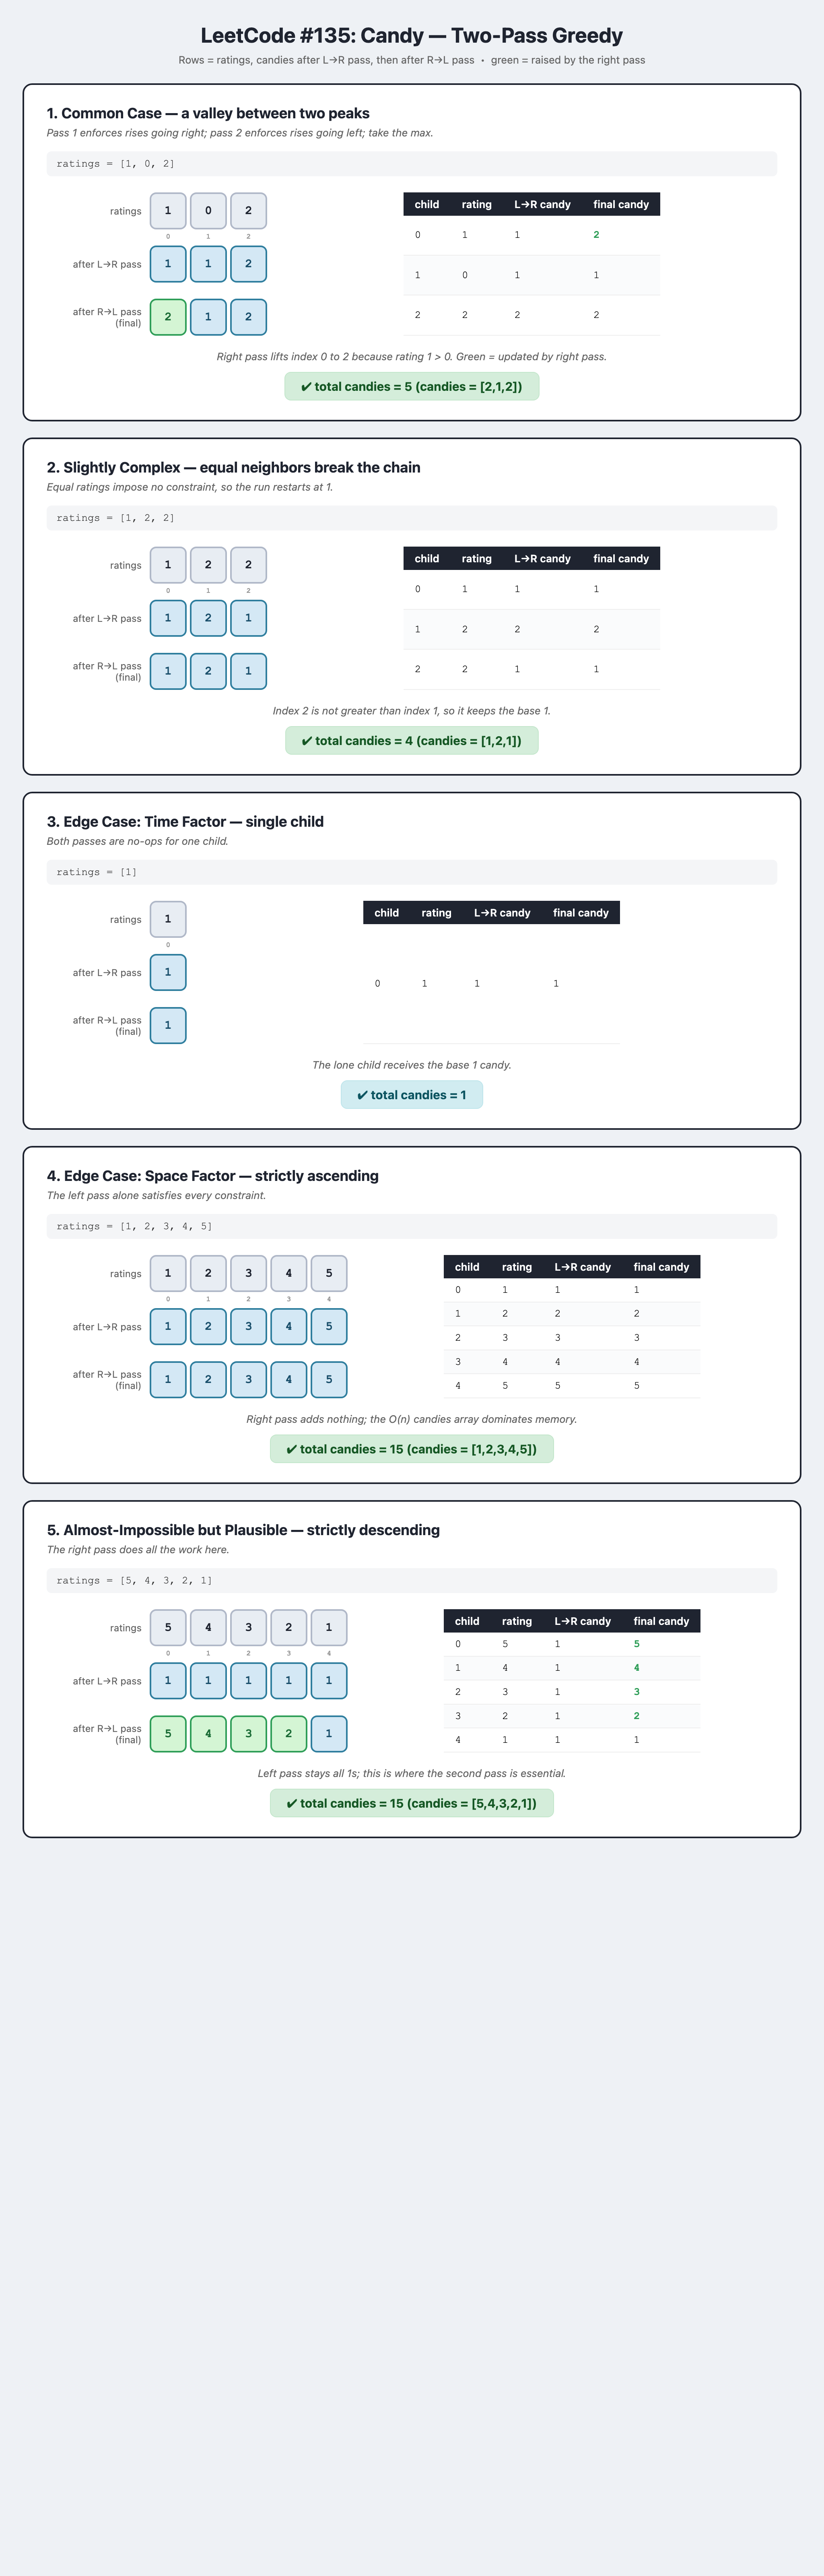